# Learning not to mix tasks: 16-task multi-MNIST

The experiment of `fully_connected.ipynb`, moved from multi-GEOFF to multi-MNIST with 16 tasks (and 16 times the hidden units of a 1-task network). In a fully connected network
there are no distractors to remove; the question is whether our method from `distractors.ipynb` learns to keep the
tasks' information apart, and so does as well as with the ideal connectivity, which builds the problem's structure in.

**Problem.** 16-task multi-MNIST, as in the connectivity paper: each sample concatenates 16 independently drawn MNIST
training images, and each task's target is its own image's label. The images are downsampled to 14×14 by averaging
2×2 blocks, which keeps the 16-task runs to minutes. Each pixel is centered on its mean over the training
set, and all pixels are scaled by one standard deviation over every pixel (scaling each pixel by its own would blow
rarely-lit pixels up to values near 250, which would collapse Autostep's step-sizes through its per-row
normalization). It is non-stationary: every 125 steps, one task (chosen at random) gets a new random mapping from digits to
labels, so each task changes about every 2000 steps. The loss is the sum of each task's softmax cross-entropy.

**Networks.** 3136 inputs → 80 LTU hidden units → 160 linear outputs (16 groups of 10 logits), each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 5 hidden units per task, each reading only its own task's image and feeding only its own task's
  logits.

**Learners.** As in `fully_connected.ipynb`, with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$:
- *ours*: centered hidden units with a matching centered backward pass, and input weights starting at
  $U(-\alpha_0, \alpha_0)$;
- *standard Autostep*: raw hidden units, and input weights starting LeCun uniform.

Each learner trains both networks. 1000k steps and 10 seeds; seed $s$ gives every run the same initial-weight draw, images and
label changes.

**Hypotheses**, on the online accuracy (over every task) averaged over the last 10% of training, pooled over seeds:
- **H1**, ours learns not to mix: fully connected, ours is at most 1 percentage point below ours with ideal
  connectivity.
- **H2**, mixing is a real cost: fully connected, standard Autostep is more than 1 percentage point below standard
  Autostep with ideal connectivity.

**Diagnostics**, fixed in advance, for the fully connected runs:
1. *Path purity*: the share of each output's input → hidden → output path weight (the product of $|w|$ along the
   path) that starts at its own task's inputs, averaged over outputs. 1 means the tasks never mix, 1/16 that they mix
   evenly.
2. How the 80 hidden units split between the tasks at the end, counting each unit for the task whose outputs it feeds
   most. An uneven split costs capacity even without mixing.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 16
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 5                # the ideal network's units per task; the fully connected one has as many in total

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 10
N_WINDOWS = 250                      # each window records its mean loss, accuracy and path purity

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')
N_HIDDEN = N_TASKS * N_HIDDEN_PER_TASK
N_OUTPUTS = N_TASKS * N_CLASSES

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum():,} weights' for k in LAYERS))

ideal connectivity: w1 15,680 weights, w2 800 weights
fully connected: w1 250,880 weights, w2 12,800 weights


## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    return Learner(w, OPTIMIZER.init(w), jnp.full(N_HIDDEN, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25))


def forward(w, x, learner, masks, ours):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    h = jnp.append(h, 1.0)
    y_hat = (w['w2'] * masks['w2']) @ h
    return y_hat, ({'w1': x[None], 'w2': h[None]}, mean, slope)


def learner_step(learner, x, labels, masks, ours):
    # One online Autostep update on the summed softmax cross-entropy of every task. Returns the new learner, the loss
    # and the fraction of tasks classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, ours)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope), loss, jnp.mean(logits.argmax(-1) == labels)

## Training

In [6]:
def path_purity(w):
    # The share of each output's input -> hidden -> output path weight (the product of |w| along the path) that starts
    # at its own task's inputs, averaged over outputs. Biases are left out.
    reads = jnp.abs(w['w1'][:, :-1]).reshape(N_HIDDEN, N_TASKS, N_PIXELS).sum(-1)      # (hidden, input task)
    paths = jnp.abs(w['w2'][:, :-1]) @ reads                                            # (output, input task)
    return jnp.mean(paths[jnp.arange(N_OUTPUTS), output_task] / jnp.maximum(paths.sum(-1), 1e-30))


def train(key, stream, masks, ours):
    # Step 1 on its own, then NUM_STEPS online steps in windows. Returns the mean loss and accuracy of every window, the
    # path purity at its end, and |w2| at the end of training.
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, masks, ours)
        return (learner, stream), (loss, accuracy)

    def window(carry, _):
        carry, (loss, accuracy) = jax.lax.scan(one_step, carry, length=NUM_STEPS // N_WINDOWS)
        return carry, {'loss': loss.mean(), 'accuracy': accuracy.mean(), 'purity': path_purity(carry[0].w)}

    stream, (x, labels) = next_sample(stream)
    learner, _, _ = learner_step(init_learner(key, masks, ours), x, labels, masks, ours)
    (learner, _), records = jax.lax.scan(window, (learner, stream), length=N_WINDOWS)
    return {**records, 'final_w2': jnp.abs(learner.w['w2'])}


def run(network, ours):
    # Trains one learner (ours, or standard Autostep) on `network` (a key of MASKS) on every seed, vmapped into one scan.
    # Seed s uses init key s and stream s for every run, so runs are paired. Returns per-seed records: loss, accuracy
    # and purity (seed, window), and final_w2 (seed, ...).
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS)
    streams = jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), N_SEEDS))
    records = jax.jit(jax.vmap(lambda key, stream: train(key, stream, MASKS[network], ours)))(keys, streams)
    return jax.tree.map(np.asarray, records)

## Results

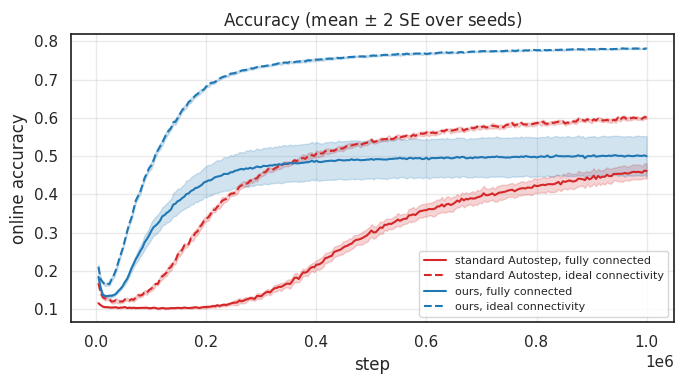

standard Autostep, fully connected     online accuracy 45.30%
standard Autostep, ideal connectivity  online accuracy 59.72%
ours, fully connected                  online accuracy 50.07%
ours, ideal connectivity               online accuracy 78.07%
H1, ours fully connected vs ideal connectivity: -28.0 points (± 5.1): failed
H2, standard Autostep fully connected vs ideal connectivity: -14.4 points (± 2.0): held


In [7]:
runs = {'standard Autostep, fully connected': run('fully connected', ours=False),
        'standard Autostep, ideal connectivity': run('ideal connectivity', ours=False),
        'ours, fully connected': run('fully connected', ours=True),
        'ours, ideal connectivity': run('ideal connectivity', ours=True)}
# Color by learner; dashed for the ideal connectivity.
STYLES = {'standard Autostep, fully connected': ('tab:red', '-'),
          'standard Autostep, ideal connectivity': ('tab:red', '--'),
          'ours, fully connected': ('tab:blue', '-'), 'ours, ideal connectivity': ('tab:blue', '--')}

window_ends = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)
plt.figure(figsize=(7, 4))
for label, res in runs.items():
    mean = res['accuracy'].mean(0)
    sem = res['accuracy'].std(0) / np.sqrt(N_SEEDS)
    color, linestyle = STYLES[label]
    plt.plot(window_ends, mean, color=color, ls=linestyle, lw=1.5, label=label)
    plt.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)
plt.xlabel('step')
plt.ylabel('online accuracy')
plt.title('Accuracy (mean $\\pm$ 2 SE over seeds)')
plt.grid(alpha=0.4)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Each seed's online accuracy over the last FINAL_FRACTION of training.
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)
accuracy = {label: res['accuracy'][:, final].mean(1) for label, res in runs.items()}
for label, a in accuracy.items():
    print(f'{label:<38} online accuracy {a.mean():.2%}')


def gap(learner):
    # The per-seed gap in accuracy of the fully connected run to the ideal connectivity on the same seed: its mean and
    # 2 SE.
    g = accuracy[f'{learner}, fully connected'] - accuracy[f'{learner}, ideal connectivity']
    return g.mean(), 2 * g.std() / np.sqrt(N_SEEDS)


held = lambda ok: 'held' if ok else 'failed'
h1, h1_se = gap('ours')
h2, h2_se = gap('standard Autostep')
print(f'H1, ours fully connected vs ideal connectivity: {100 * h1:+.1f} points (± {100 * h1_se:.1f}): '
      f'{held(h1 >= -ACCURACY_TOLERANCE)}')
print(f'H2, standard Autostep fully connected vs ideal connectivity: {100 * h2:+.1f} points (± {100 * h2_se:.1f}): '
      f'{held(h2 < -ACCURACY_TOLERANCE)}')

### Diagnostics: mixing and unit allocation

Path purity over training for the fully connected runs (mean over seeds, with the 5th to 95th percentile over seeds
shaded), and how the hidden units split between the tasks at the end.

standard Autostep, fully connected: hidden units per task at the end, fewest 0.6 and most 10.9 on average over seeds; seeds with an even split 0%
ours, fully connected: hidden units per task at the end, fewest 0.0 and most 21.7 on average over seeds; seeds with an even split 0%


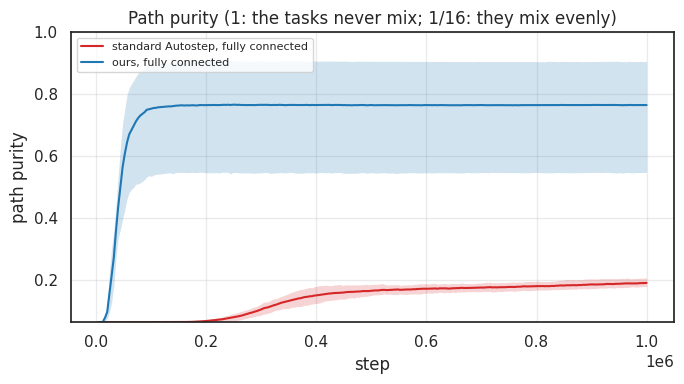

In [8]:
def units_per_task(w2):
    # How many hidden units feed each task's outputs most (by the sum of |w| to that task's outputs), sorted.
    feeds = np.stack([w2[..., output_task == t, :-1].sum(-2) for t in range(N_TASKS)], -1)    # (..., hidden, task)
    return np.sort(np.stack([(feeds.argmax(-1) == t).sum(-1) for t in range(N_TASKS)], -1), -1)


plt.figure(figsize=(7, 4))
for label in ('standard Autostep, fully connected', 'ours, fully connected'):
    purity = runs[label]['purity']                                           # (seed, window)
    color, _ = STYLES[label]
    plt.plot(window_ends, purity.mean(0), color=color, lw=1.5, label=label)
    plt.fill_between(window_ends, *np.percentile(purity, [5, 95], axis=0), color=color, alpha=0.2, lw=0)
    counts = units_per_task(runs[label]['final_w2'])                         # (seed, task), sorted
    print(f'{label}: hidden units per task at the end, fewest {counts[:, 0].mean():.1f} and most '
          f'{counts[:, -1].mean():.1f} on average over seeds; seeds with an even split {np.mean(counts[:, 0] == counts[:, -1]):.0%}')
plt.ylim(1 / N_TASKS, 1.0)
plt.xlabel('step')
plt.ylabel('path purity')
plt.title(f'Path purity (1: the tasks never mix; 1/{N_TASKS}: they mix evenly)')
plt.grid(alpha=0.4)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Results

- **H1 failed.** Fully connected, ours reaches 50.1% online accuracy against 78.1% with ideal connectivity: −28.0
  points (± 5.1, 2 SE over paired seeds). It levels off by about 300k steps.
- **H2 held.** Fully connected, standard Autostep is −14.4 points (± 2.0): 45.3% against 59.7%. It is still improving
  at 1M steps.
- Fully connected, ours is 4.8 points above standard Autostep; with ideal connectivity, 18.4 points.
- **Diagnostics.** Ours' path purity levels off at about 0.77 (the 5th to 95th percentile over seeds is 0.55 to 0.90;
  even mixing would be 1/16), against about 0.19 for standard Autostep. Its unit allocation is extreme: in every seed
  at least one task has no unit that feeds it most, while the best-served task gets about 22 of the 80 units on
  average. Standard Autostep's split is less extreme (fewest 0.6 and most 10.9 on average).
- With ideal connectivity, both learners land within 2 points of their 2-task accuracy (ours 78.1% here, 77.8% with 2
  tasks), as expected: the sub-networks are independent, and each task changes at the same rate.